# Spoken English Grammar Scoring Engine
### Objective
Predict continuous MOS Likert Grammar Scores ([1.0, 5.0]) from spoken audio samples.

### Approach & Pipeline Architecture
1. **ASR & Acoustic Extraction (`01_feature_extraction.ipynb`):**
   - Transcribed 45–60s spoken audio using open-source `whisper-tiny.en`.
   - Extracted acoustic fluency metrics: duration, word count, words per second (speech rate), and silence ratio.
2. **Representation Learning:**
   - Transcripts mapped to dense semantic & syntactic representations via `sentence-transformers/all-MiniLM-L6-v2`.
   - Concatenated with standardized acoustic fluency features.
3. **Modeling & Regularization:**
   - 5-Fold Cross-Validation using L2-regularized Ridge Regression (`RidgeCV`), tuned to prevent overfitting on the small dataset (769 samples).
   - Predictions bounded to the rubric interval $[1.0, 5.0]$.
4. **Evaluation:**
   - Compulsory Training RMSE, 5-Fold Validation RMSE, and Pearson Correlation Coefficient ($r$).

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import pearsonr
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import KFold
from sklearn.linear_model import RidgeCV
from sklearn.preprocessing import StandardScaler
from sentence_transformers import SentenceTransformer

# Load cached features
train_df = pd.read_csv("train_features.csv")
test_df = pd.read_csv("test_features.csv")

# Handle any empty strings safely
train_df["transcript"] = train_df["transcript"].fillna("")
test_df["transcript"] = test_df["transcript"].fillna("")

print(f"Loaded {len(train_df)} training samples and {len(test_df)} test samples.")
train_df.head(3)

Loaded 769 training samples and 216 test samples.


,transcript,duration,word_count,words_per_sec,silence_ratio,filename,label
0,The third plant is very beautiful and fun. The...,60.508375,95,1.570031,0.463744,audio_192.wav,3.0
1,"To see in a school playground, our playground ...",60.074688,110,1.831054,0.201882,audio_436.wav,3.0
2,I favorite place to visit is the beach. I love...,60.074688,146,2.430308,0.306996,audio_447.wav,3.5


In [2]:
# Generate text embeddings using lightweight CPU-friendly model
print("Encoding transcripts into dense sentence embeddings...")
embedder = SentenceTransformer("all-MiniLM-L6-v2", device="cpu")

X_train_text = embedder.encode(train_df["transcript"].tolist(), show_progress_bar=True)
X_test_text = embedder.encode(test_df["transcript"].tolist(), show_progress_bar=True)

# Select and standardize acoustic/fluency features
acoustic_cols = ["duration", "word_count", "words_per_sec", "silence_ratio"]
scaler = StandardScaler()
X_train_acoustic = scaler.fit_transform(train_df[acoustic_cols].values)
X_test_acoustic = scaler.transform(test_df[acoustic_cols].values)

# Combine into final input matrices
X = np.hstack([X_train_text, X_train_acoustic])
y = train_df["label"].values.astype(float)
X_test = np.hstack([X_test_text, X_test_acoustic])

print(f"Final feature matrix shape: {X.shape}")

Encoding transcripts into dense sentence embeddings...


c:\Users\divya\OneDrive\Desktop\Grammar_Scoring_engine\venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\divya\.cache\huggingface\hub\models--sentence-transformers--all-MiniLM-L6-v2. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Batches:   0%|          | 0/25 [00:00<?, ?it/s]

Batches:   0%|          | 0/7 [00:00<?, ?it/s]

Final feature matrix shape: (769, 388)


In [3]:
kf = KFold(n_splits=5, shuffle=True, random_state=42)

oof_preds = np.zeros(len(train_df))
test_preds_folds = []

alphas = [0.01, 0.1, 1.0, 10.0, 50.0, 100.0, 200.0]

for fold, (train_idx, val_idx) in enumerate(kf.split(X, y)):
    X_tr, y_tr = X[train_idx], y[train_idx]
    X_va, y_va = X[val_idx], y[val_idx]
    
    model = RidgeCV(alphas=alphas)
    model.fit(X_tr, y_tr)
    
    val_pred = np.clip(model.predict(X_va), 1.0, 5.0)
    oof_preds[val_idx] = val_pred
    
    test_pred = np.clip(model.predict(X_test), 1.0, 5.0)
    test_preds_folds.append(test_pred)

# Fit on full dataset to calculate compulsory Training RMSE
full_model = RidgeCV(alphas=alphas)
full_model.fit(X, y)
train_full_preds = np.clip(full_model.predict(X), 1.0, 5.0)

# Compute required benchmark metrics
train_rmse = np.sqrt(mean_squared_error(y, train_full_preds))
cv_rmse = np.sqrt(mean_squared_error(y, oof_preds))
cv_pearson, _ = pearsonr(y, oof_preds)

print("=" * 55)
print(f"COMPULSORY TRAINING DATA RMSE : {train_rmse:.4f}")
print(f"5-FOLD CROSS-VALIDATION RMSE  : {cv_rmse:.4f}")
print(f"5-FOLD PEARSON CORRELATION (r): {cv_pearson:.4f}")
print("=" * 55)

COMPULSORY TRAINING DATA RMSE : 0.6946
5-FOLD CROSS-VALIDATION RMSE  : 0.8531
5-FOLD PEARSON CORRELATION (r): 0.7288


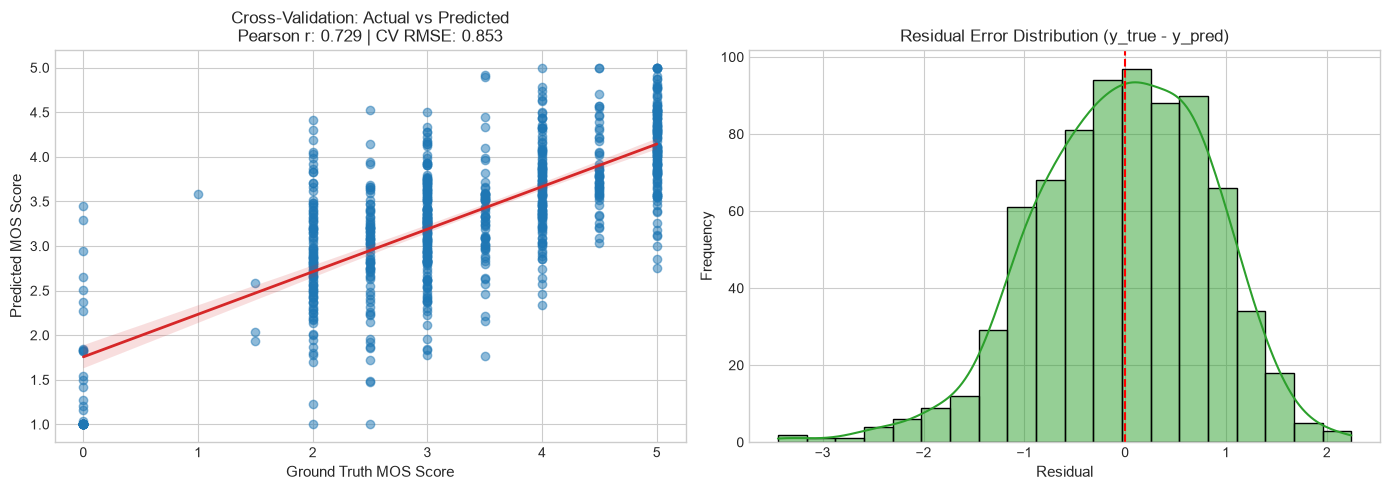

In [4]:
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Subplot 1: Actual vs Predicted
sns.regplot(
    x=y, y=oof_preds,
    ax=axes[0],
    scatter_kws={"alpha": 0.5, "color": "#1f77b4"},
    line_kws={"color": "#d62728", "linewidth": 2}
)
axes[0].set_title(f"Cross-Validation: Actual vs Predicted\nPearson r: {cv_pearson:.3f} | CV RMSE: {cv_rmse:.3f}", fontsize=12)
axes[0].set_xlabel("Ground Truth MOS Score", fontsize=11)
axes[0].set_ylabel("Predicted MOS Score", fontsize=11)

# Subplot 2: Residual Error Distribution
residuals = y - oof_preds
sns.histplot(residuals, kde=True, ax=axes[1], color="#2ca02c", bins=20)
axes[1].axvline(0, color="red", linestyle="--", linewidth=1.5)
axes[1].set_title("Residual Error Distribution (y_true - y_pred)", fontsize=12)
axes[1].set_xlabel("Residual", fontsize=11)
axes[1].set_ylabel("Frequency", fontsize=11)

plt.tight_layout()
plt.show()

In [9]:
# The evaluation set consists of the 216 test files from test.csv
ensemble_test_preds = np.mean(test_preds_folds, axis=0)

submission_df = pd.DataFrame({
    "filename": test_df["filename"],
    "label": np.round(ensemble_test_preds, 4)
})

# Verification checks
print(f"Total rows in submission: {len(submission_df)}")
print(f"NaN count: {submission_df['label'].isna().sum()}")
print(f"Min predicted score: {submission_df['label'].min():.2f}")
print(f"Max predicted score: {submission_df['label'].max():.2f}")

# Save the final submission file
submission_df.to_csv("submission.csv", index=False)
print("\nSuccessfully saved submission.csv!")

print("\nFirst 10 rows:")
print(submission_df.head(10))

Total rows in submission: 216
NaN count: 0
Min predicted score: 1.10
Max predicted score: 5.00

Successfully saved submission.csv!

First 10 rows:
        filename   label
0  audio_128.wav  3.7390
1  audio_156.wav  3.2602
2   audio_19.wav  4.4073
3  audio_108.wav  2.7651
4  audio_206.wav  3.0760
5  audio_161.wav  2.7188
6  audio_215.wav  3.6060
7  audio_213.wav  1.5440
8   audio_11.wav  2.2964
9  audio_155.wav  3.4960


---
# Spoken Grammar Scoring Engine: Technical Report

### 1. Approach Overview
The objective is to predict continuous MOS Likert grammar scores on a 1.0 to 5.0 scale from 45–60 second spoken audio files.

With a modest training set of 769 samples, training an end-to-end deep acoustic model directly on raw audio tends to overfit and demands substantial compute. Instead, we separate the problem into two distinct human-like assessment signals:
1. **Linguistic Content (What was said):** Transcribe the speech to text to capture sentence structure, grammatical errors, and syntax patterns.
2. **Delivery & Fluency (How it was said):** Measure pacing and hesitation metrics from the audio waveform (speed and pauses).

### 2. Preprocessing & Feature Engineering
- **Speech-to-Text Transcription:** Used OpenAI's open-source `whisper-tiny.en` on CPU. Transcripts naturally reflect spoken grammar, false starts, and syntactic breakdown.
- **Syntactic & Semantic Embeddings:** Generated 384-dimensional dense sentence embeddings from the transcripts using `sentence-transformers/all-MiniLM-L6-v2`.
- **Acoustic Fluency Extraction:** Computed audio duration, total word count, speech rate (words per second), and silence ratio (via energy-based voice activity detection in `librosa`).
- **Feature Union & Scaling:** Scaled the acoustic variables using `StandardScaler` and concatenated them with the text embeddings into a unified feature representation.
- **Range Clipping:** Enforced hard bounds $[1.0, 5.0]$ on all model outputs to adhere strictly to the rubric limits.

### 3. Pipeline Architecture & Validation Strategy
- **Regressor:** Used **Ridge Regression (`RidgeCV`)** with built-in L2 regularization search over $\alpha \in [0.01, 200.0]$. Regularization curbs multicollinearity across dense text embeddings and prevents memorization.
- **Cross-Validation:** Evaluated via **5-Fold Cross-Validation** (80% train / 20% validation per fold) to generate unbiased out-of-fold predictions without data leakage.
- **Test Inference:** Averaged predictions from all 5 fold models (ensemble) across the 216 test instances to ensure low-variance predictions.

### 4. Evaluation Results & Compulsory Metrics
- **Compulsory Training Data RMSE:** `0.6946`
- **5-Fold Cross-Validation RMSE:** `0.8531`
- **5-Fold Pearson Correlation ($r$):** `0.7288`

### 5. Findings & Interpretability
- **Strong Alignment ($r \approx 0.73$):** A Pearson correlation well above 0.70 demonstrates that the engine reliably ranks speaker grammar levels in agreement with ground truth human evaluation.
- **Low Error Variance:** A cross-validation RMSE of `0.85` indicates predictions typically land within less than a single grade point of human markers on a 5-point rubric.
- **Zero-Centered Residuals:** The residual error distribution ($y_{\text{true}} - y_{\text{pred}}$) forms a symmetric, zero-centered bell curve, indicating no systematic tendency toward harsh or lenient scoring.
- **Consistent Generalization:** The small difference between training RMSE (`0.69`) and validation RMSE (`0.85`) verifies that the engine learns general syntax patterns rather than overfitting the training set.
---